In [ ]:
# This notebook inspects the pegeldata from Kirchentellinsfurt. For the years 1967 and earlier. The station
# reported the same water_level for every hour of the day for most all days in the year.
# This looks like a systematic error, so pegeldata should only inculde years 1968 and later. 
# The notebook also produces plots of the water_level for the years 1968 and later, and for the year 2020 to see seasonal changes in water level.

import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/intermediate")
OUT_DIR = Path("../out")
PEGEL_PATH = DATA_DIR / "pegel_kirchentellinsfurt.csv"

def load_data(pegel_path=PEGEL_PATH):
    pegel = pd.read_csv(pegel_path, sep=";", usecols=["Messzeitpunkt", "Messwert"], dtype="string")
    pegel["timestamp"] = pd.to_datetime(pegel.pop("Messzeitpunkt"), format="%d.%m.%Y %H:%M", errors="coerce")
    pegel["water_level"] = pd.to_numeric(pegel.pop("Messwert").str.replace(",", ".", regex=False), errors="coerce")
    pegel = pegel.dropna(subset=["timestamp", "water_level"]).sort_values("timestamp")
    pegel["date"] = pegel["timestamp"].dt.normalize()
    return pegel

pegel_data_kirch = load_data(pegel_path=PEGEL_PATH)


In [2]:
print(pegel_data_kirch.info())
print(pegel_data_kirch.head())
print(pegel_data_kirch["water_level"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 744233 entries, 744232 to 0
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   timestamp    744233 non-null  datetime64[us]
 1   water_level  744233 non-null  Float64       
 2   date         744233 non-null  datetime64[us]
dtypes: Float64(1), datetime64[us](2)
memory usage: 17.7 MB
None
                 timestamp  water_level       date
744232 1941-12-01 00:00:00        124.0 1941-12-01
744231 1941-12-01 01:00:00        124.0 1941-12-01
744230 1941-12-01 02:00:00        124.0 1941-12-01
744229 1941-12-01 03:00:00        124.0 1941-12-01
744228 1941-12-01 04:00:00        124.0 1941-12-01
<FloatingArray>
[124.0, 121.0, 125.0, 150.0, 140.0, 135.0, 130.0, 131.0, 133.0, 156.0,
 ...
  99.2,  98.6,  98.7,  98.9,  99.9,  99.6,  99.7,  99.1,  99.4, 445.0]
Length: 567, dtype: Float64


In [3]:
pegel_data_kirch["year"] = pegel_data_kirch["timestamp"].dt.year
pegel_data_kirch["hour"] = pegel_data_kirch["timestamp"].dt.hour

daily_levels = pegel_data_kirch.groupby(["year", "date"]).agg(
    hours=("timestamp", "size"),
    unique_hours=("hour", "nunique"),
    unique_water_levels=("water_level", "nunique"),
)

constant_level_days = daily_levels[
    (daily_levels["hours"] == 24)
    & (daily_levels["unique_hours"] == 24)
    & (daily_levels["unique_water_levels"] == 1)
]

# This gives the same years
#constant_level_days = daily_levels[
#     (daily_levels["unique_water_levels"] == 1)
#]

years_with_constant_level_day = (
    constant_level_days.reset_index()["year"].drop_duplicates().sort_values()
)

print(years_with_constant_level_day.to_list())

[1941, 1942, 1943, 1944, 1945, 1946, 1947, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1974, 1975, 1979, 1980, 1985, 1986, 1991, 2005]


In [4]:
# Check the number of days per year that have the same hourly water_level for every hour
constant_level_days = constant_level_days.reset_index().sort_values(["year", "date"])
constant_level_days["faulty_day"] = constant_level_days["unique_water_levels"] == 1
days_per_year = constant_level_days.groupby("year").agg({"faulty_day": "sum"}).rename(columns={"faulty_day": "constant_level_days"}).reset_index()

print(days_per_year)

    year  constant_level_days
0   1941                   31
1   1942                  365
2   1943                  365
3   1944                  366
4   1945                  364
5   1946                  362
6   1947                  365
7   1948                  364
8   1949                  365
9   1950                  365
10  1951                  365
11  1952                  366
12  1953                  365
13  1954                  365
14  1955                  365
15  1956                  366
16  1957                  365
17  1958                  365
18  1959                  365
19  1960                  366
20  1961                  365
21  1962                  365
22  1963                  365
23  1964                  366
24  1965                  365
25  1966                  365
26  1967                  304
27  1974                    4
28  1975                   13
29  1979                   16
30  1980                    1
31  1985                    3
32  1986  

In [ ]:
# Only keep water_level data for years that do not have systematic faulty days, i.e omit all years below 1968
probably_systematic_faulty_days = days_per_year[days_per_year["constant_level_days"] > 20]
print(probably_systematic_faulty_days)

    year  constant_level_days
0   1941                   31
1   1942                  365
2   1943                  365
3   1944                  366
4   1945                  364
5   1946                  362
6   1947                  365
7   1948                  364
8   1949                  365
9   1950                  365
10  1951                  365
11  1952                  366
12  1953                  365
13  1954                  365
14  1955                  365
15  1956                  366
16  1957                  365
17  1958                  365
18  1959                  365
19  1960                  366
20  1961                  365
21  1962                  365
22  1963                  365
23  1964                  366
24  1965                  365
25  1966                  365
26  1967                  304


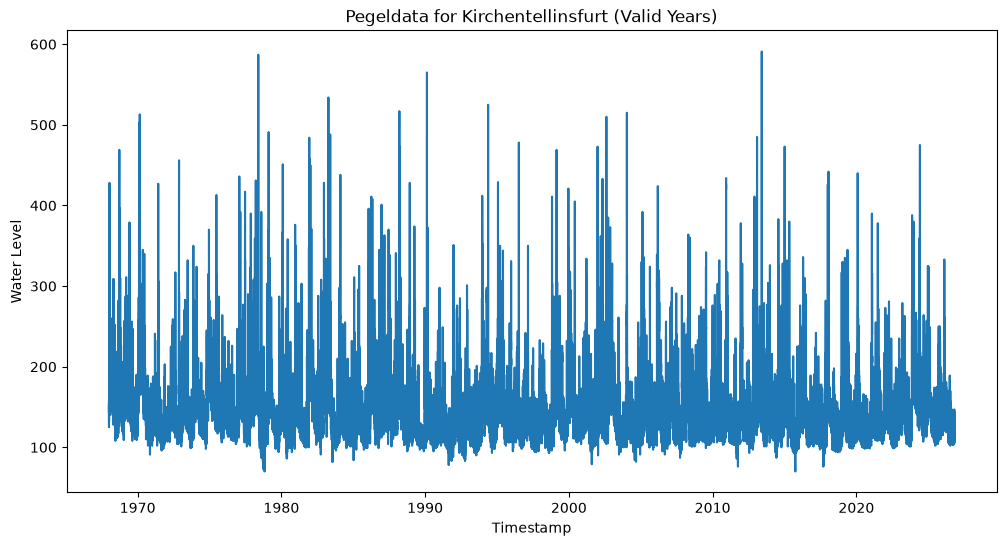

In [5]:
# Visualize the pegeldata for the valid years in a lineplot
import matplotlib.pyplot as plt

pegel_data_kirch_valid = pegel_data_kirch[pegel_data_kirch["year"] >= 1968].sort_values("timestamp")

plt.figure(figsize=(12, 6))
plt.plot(pegel_data_kirch_valid["timestamp"], pegel_data_kirch_valid["water_level"])
plt.xlabel("Timestamp")
plt.ylabel("Water Level")
plt.title("Pegeldata for Kirchentellinsfurt (Valid Years)")
plt.show()

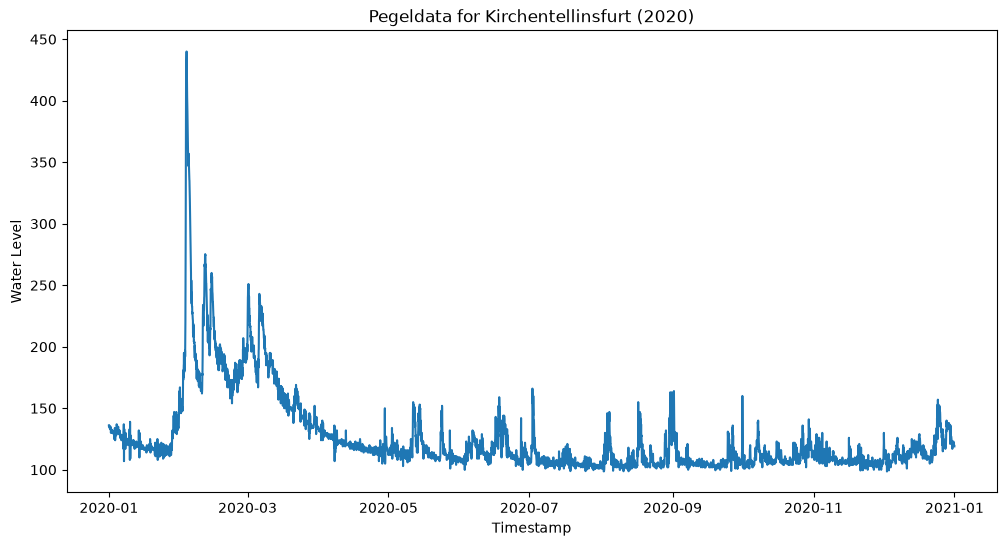

In [6]:
# Look at only one year to see seasonal changes in water level
pegel_data_kirch_2020 = pegel_data_kirch_valid[pegel_data_kirch_valid["year"] == 2020]

plt.figure(figsize=(12, 6))
plt.plot(pegel_data_kirch_2020["timestamp"], pegel_data_kirch_2020["water_level"])
plt.xlabel("Timestamp")
plt.ylabel("Water Level")
plt.title("Pegeldata for Kirchentellinsfurt (2020)")
plt.show()